In this assignment, I am using the CIFAR-10 dataset, which consists of 60,000 color images in 10 classes, with 6,000 images per class. The goal of this assignment is to learn how a machine learning model adapts when new data are generated. We  verify which one performed better. that is either by retrianing the whole dataset of whether to retains just the new data generated.

In [1]:
#Imort the libraries
import copy
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

In [2]:
#Load and preprocess CIFAR-10
transform = transforms.Compose([
    transforms.ToTensor(),

    # Scale pixel values from [0, 1] to approximately [-1, 1]
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

full_train = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(full_train))
print("Test images:", len(test_dataset))
print("Classes:", full_train.classes)

Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [3]:
#Split the training data into two subsets
targets = np.array(full_train.targets)
rng = np.random.default_rng(42)

# Indices for the two complete subsets
a_indices = np.flatnonzero(targets < 5)
b_indices = np.flatnonzero(targets >= 5)

subset_a = Subset(full_train, a_indices.tolist())
subset_b = Subset(full_train, b_indices.tolist())


def balanced_split(class_ids, train_fraction=0.8): # this ensures that each subset has a balanced number of samples per class.
    train_indices = []
    val_indices = []

    for class_id in class_ids:
        indices = np.flatnonzero(targets == class_id)
        indices = rng.permutation(indices)

        split_point = int(len(indices) * train_fraction)

        train_indices.extend(indices[:split_point].tolist())
        val_indices.extend(indices[split_point:].tolist())

    return train_indices, val_indices


a_train_indices, a_val_indices = balanced_split(range(5))
b_train_indices, b_val_indices = balanced_split(range(5, 10))

a_train = Subset(full_train, a_train_indices)
a_val = Subset(full_train, a_val_indices)

# Reserve these for the later adaptation stage
b_train = Subset(full_train, b_train_indices)
b_val = Subset(full_train, b_val_indices)


def show_counts(name, indices):
    labels, counts = np.unique(
        targets[np.array(indices)],
        return_counts=True
    )

    print(f"\n{name}: {len(indices)} images")

    for label, count in zip(labels, counts):
        print(f"  {full_train.classes[label]}: {count}")


show_counts("Subset A training", a_train_indices)
show_counts("Subset A validation", a_val_indices)
show_counts("Subset B training", b_train_indices)
show_counts("Subset B validation", b_val_indices)


Subset A training: 20000 images
  airplane: 4000
  automobile: 4000
  bird: 4000
  cat: 4000
  deer: 4000

Subset A validation: 5000 images
  airplane: 1000
  automobile: 1000
  bird: 1000
  cat: 1000
  deer: 1000

Subset B training: 20000 images
  dog: 4000
  frog: 4000
  horse: 4000
  ship: 4000
  truck: 4000

Subset B validation: 5000 images
  dog: 1000
  frog: 1000
  horse: 1000
  ship: 1000
  truck: 1000


Create data loaders to feeds the model in small batches of images. Training data is shuffled so the model sees a different order each epoch

In [4]:
#Create data loaders
batch_size = 128

a_train_loader = DataLoader(
    a_train,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

a_val_loader = DataLoader(
    a_val,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
)

In [5]:
#create a simple CNN
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 32 × 32 → 16 × 16

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 16 × 16 → 8 × 8

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)   # 8 × 8 → 4 × 4
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = SimpleCNN(num_classes=5)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print(model)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True

In [6]:
#Train and validate the initial model
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    # Enable gradients for training; disable them for validation
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(non_blocking=True)
            labels = labels.to(non_blocking=True)

            if training:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

            predictions = outputs.argmax(dim=1)

            total_loss += loss.item() * labels.size(0)
            total_correct += (predictions == labels).sum().item()
            total_images += labels.size(0)

    return (
        total_loss / total_images,
        total_correct / total_images
    )


epochs = 15

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_accuracy = -1.0
best_weights = None
best_epoch = 0

# Train on Subset A
for epoch in range(epochs):
    train_loss, train_accuracy = run_epoch(
        model, a_train_loader, optimizer
    )

## Validate on Subset A    
    val_loss, val_accuracy = run_epoch(
        model, a_val_loader
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_weights = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.2%} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {val_accuracy:.2%}"
    )

# Restore the model from its best validation epoch
model.load_state_dict(best_weights)

print(
    f"\nBest validation accuracy: {best_val_accuracy:.2%} "
    f"(epoch {best_epoch})"
)

Epoch 01/15 | Train loss: 0.9747 | Train accuracy: 60.32% | Val loss: 0.8452 | Val accuracy: 65.62%
Epoch 02/15 | Train loss: 0.7139 | Train accuracy: 72.69% | Val loss: 0.7062 | Val accuracy: 72.66%
Epoch 03/15 | Train loss: 0.6096 | Train accuracy: 76.98% | Val loss: 0.5748 | Val accuracy: 78.04%
Epoch 04/15 | Train loss: 0.5453 | Train accuracy: 79.46% | Val loss: 0.5321 | Val accuracy: 79.76%
Epoch 05/15 | Train loss: 0.4776 | Train accuracy: 82.45% | Val loss: 0.5243 | Val accuracy: 80.58%
Epoch 06/15 | Train loss: 0.4339 | Train accuracy: 84.11% | Val loss: 0.5356 | Val accuracy: 80.66%
Epoch 07/15 | Train loss: 0.3891 | Train accuracy: 85.91% | Val loss: 0.5123 | Val accuracy: 80.70%
Epoch 08/15 | Train loss: 0.3582 | Train accuracy: 86.96% | Val loss: 0.5103 | Val accuracy: 82.38%
Epoch 09/15 | Train loss: 0.3115 | Train accuracy: 88.59% | Val loss: 0.4758 | Val accuracy: 83.22%
Epoch 10/15 | Train loss: 0.2716 | Train accuracy: 90.14% | Val loss: 0.5367 | Val accuracy: 81.86%


**Simulating Data Distribution Shift**

In [7]:
# Keep the original A model for comparison
initial_model = copy.deepcopy(model).cpu()

# Continue from the learned A weights because it is a stateful training where the old model is only improved upon.
stateful_model = copy.deepcopy(initial_model)

# Expand the classifier to support all ten classes
old_layer = stateful_model.classifier[-1]
new_layer = nn.Linear(old_layer.in_features, 10)

with torch.no_grad():
    new_layer.weight[:5].copy_(old_layer.weight)
    new_layer.bias[:5].copy_(old_layer.bias)

stateful_model.classifier[-1] = new_layer

# Subset B loaders
b_train_loader = DataLoader(
    b_train, batch_size=128, shuffle=True, num_workers=0
)

b_val_loader = DataLoader(
    b_val, batch_size=128, shuffle=False, num_workers=0
)

criterion = nn.CrossEntropyLoss()

optimizer_b = torch.optim.Adam(
    stateful_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

**Now train on B and select the best model using B’s validation accuracy**

In [8]:
#Evaluate the initial model on Subset B and record the performance
epochs = 15
best_b_accuracy = -1.0
best_b_weights = None

# Old-class accuracy before learning B
_, a_before = run_epoch(initial_model, a_val_loader)

for epoch in range(epochs):
    train_loss, train_accuracy = run_epoch(
        stateful_model, b_train_loader, optimizer_b
    )

    val_loss, val_accuracy = run_epoch(
        stateful_model, b_val_loader
    )

    if val_accuracy > best_b_accuracy:
        best_b_accuracy = val_accuracy
        best_b_weights = copy.deepcopy(stateful_model.state_dict())

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"B train loss: {train_loss:.4f} | "
        f"B train accuracy: {train_accuracy:.2%} | "
        f"B val loss: {val_loss:.4f} | "
        f"B val accuracy: {val_accuracy:.2%}"
    )

stateful_model.load_state_dict(best_b_weights)

# Evaluate retention of A and learning of B
_, a_after = run_epoch(stateful_model, a_val_loader)
_, b_after = run_epoch(stateful_model, b_val_loader)

print(f"\nSubset A before training on B: {a_before:.2%}")
print(f"Subset A after training on B:  {a_after:.2%}")
print(f"Subset B after training on B:  {b_after:.2%}")
print(f"Drop in A accuracy: {(a_before - a_after) * 100:.2f} percentage points")

Epoch 01/15 | B train loss: 0.6869 | B train accuracy: 75.20% | B val loss: 0.3828 | B val accuracy: 86.04%
Epoch 02/15 | B train loss: 0.3591 | B train accuracy: 87.20% | B val loss: 0.3678 | B val accuracy: 86.04%
Epoch 03/15 | B train loss: 0.2854 | B train accuracy: 89.75% | B val loss: 0.3977 | B val accuracy: 85.48%
Epoch 04/15 | B train loss: 0.2502 | B train accuracy: 91.00% | B val loss: 0.3002 | B val accuracy: 89.02%
Epoch 05/15 | B train loss: 0.1998 | B train accuracy: 93.09% | B val loss: 0.3177 | B val accuracy: 88.20%
Epoch 06/15 | B train loss: 0.1664 | B train accuracy: 94.09% | B val loss: 0.3120 | B val accuracy: 89.04%
Epoch 07/15 | B train loss: 0.1321 | B train accuracy: 95.27% | B val loss: 0.2931 | B val accuracy: 89.82%
Epoch 08/15 | B train loss: 0.1167 | B train accuracy: 95.91% | B val loss: 0.2807 | B val accuracy: 90.74%
Epoch 09/15 | B train loss: 0.0942 | B train accuracy: 96.74% | B val loss: 0.2939 | B val accuracy: 90.56%
Epoch 10/15 | B train loss: 

**Stateless retraining:  training start from scratch on A and B**

In [9]:
#Create the evaluation loaders
from torch.utils.data import ConcatDataset

def make_loader(dataset, shuffle=False):
    return DataLoader(
        dataset,
        batch_size=128,
        shuffle=shuffle,
        num_workers=0
    )

b_val_loader = make_loader(b_val)

combined_train = ConcatDataset([a_train, b_train])
combined_val = ConcatDataset([a_val, b_val])

combined_train_loader = make_loader(combined_train, shuffle=True)
combined_val_loader = make_loader(combined_val)
b_train_loader = make_loader(b_train, shuffle=True)

In [10]:
# Preserve the initial model for all comparisons
initial_model = copy.deepcopy(model).cpu()


def accuracy(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.cpu()
            labels = labels.cpu()

            predictions = model(images).argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return correct / total


initial_a_accuracy = accuracy(initial_model, a_val_loader)
initial_b_accuracy = accuracy(initial_model, b_val_loader)

print(f"Initial model — Subset A: {initial_a_accuracy:.2%}")
print(f"Initial model — Subset B: {initial_b_accuracy:.2%}")

Initial model — Subset A: 83.78%
Initial model — Subset B: 0.00%


In [11]:
#define a training function from scratch
def train_model(model, train_loader, val_loader, epochs=15):
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-4
    )

    best_accuracy = -1.0
    best_weights = None

    for epoch in range(epochs):
        train_loss, train_accuracy = run_epoch(
            model, train_loader, optimizer
        )

        val_loss, val_accuracy = run_epoch(
            model, val_loader
        )

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_weights = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Train accuracy: {train_accuracy:.2%} | "
            f"Val accuracy: {val_accuracy:.2%}"
        )

    model.load_state_dict(best_weights)
    return model

In [12]:
torch.manual_seed(42)

# New model with randomly initialized weights
stateless_model = SimpleCNN(num_classes=10)

stateless_model = train_model(
    stateless_model,
    combined_train_loader,
    combined_val_loader,
    epochs=15
)

print(
    "\nStateless combined validation accuracy:",
    f"{accuracy(stateless_model, combined_val_loader):.2%}"
)

Epoch 01/15 | Train loss: 1.3647 | Train accuracy: 50.52% | Val accuracy: 63.51%
Epoch 02/15 | Train loss: 0.9990 | Train accuracy: 64.71% | Val accuracy: 68.00%
Epoch 03/15 | Train loss: 0.8614 | Train accuracy: 69.58% | Val accuracy: 70.22%
Epoch 04/15 | Train loss: 0.7766 | Train accuracy: 72.72% | Val accuracy: 72.51%
Epoch 05/15 | Train loss: 0.7079 | Train accuracy: 75.17% | Val accuracy: 74.06%
Epoch 06/15 | Train loss: 0.6472 | Train accuracy: 77.14% | Val accuracy: 75.47%
Epoch 07/15 | Train loss: 0.6003 | Train accuracy: 78.84% | Val accuracy: 75.67%
Epoch 08/15 | Train loss: 0.5496 | Train accuracy: 80.40% | Val accuracy: 77.19%
Epoch 09/15 | Train loss: 0.5146 | Train accuracy: 81.86% | Val accuracy: 77.63%
Epoch 10/15 | Train loss: 0.4641 | Train accuracy: 83.71% | Val accuracy: 77.04%
Epoch 11/15 | Train loss: 0.4306 | Train accuracy: 84.92% | Val accuracy: 77.78%
Epoch 12/15 | Train loss: 0.3948 | Train accuracy: 85.99% | Val accuracy: 77.01%
Epoch 13/15 | Train loss: 0.

Replay the model to reminds the initail model of the old classes during adaptation. Note only A’s training images enter the memory, so that validation data does not leak into training.

**Compare all models**

In [16]:
models = {
    "Initial (5 outputs)": initial_model,
    "Stateless: A + B": stateless_model,
    "Stateful: B only": stateful_model
}

results = {}

print(
    f"{'Method':<25} {'A accuracy':>12} "
    f"{'B accuracy':>12} {'Combined':>12}"
)
print("-" * 65)

for name, trained_model in models.items():
    a_acc = accuracy(trained_model, a_val_loader)
    b_acc = accuracy(trained_model, b_val_loader)
    combined_acc = accuracy(trained_model, combined_val_loader)

    results[name] = {
        "A": a_acc,
        "B": b_acc,
        "Combined": combined_acc
    }

    print(
        f"{name:<25} {a_acc:>11.2%} "
        f"{b_acc:>11.2%} {combined_acc:>11.2%}"
    )

print("\nChange in old-class accuracy:")

for name in ["Stateful: B only"]:
    # Positive values mean a drop; negative values mean improvement
    drop = 100 * (initial_a_accuracy - results[name]["A"])

    print(f"{name}: {drop:+.2f} percentage points of drop")

Method                      A accuracy   B accuracy     Combined
-----------------------------------------------------------------
Initial (5 outputs)            83.78%       0.00%      41.89%
Stateless: A + B               73.80%      83.36%      78.58%
Stateful: B only                0.00%      90.74%      45.37%

Change in old-class accuracy:
Stateful: B only: +83.78 percentage points of drop


The initial model performed well on Subset A but could not recognize Subset B because the new classes were outside its output range. Stateless retraining on both subsets achieved the highest combined accuracy of 78.58%. Stateful training achieved 90.74% accuracy on the new classes, but its old-class accuracy dropped from 83.78% to 0%. 

These results show that continuing training only on new data was insufficient to preserve previous performance. 

**Plot performance on old and new classes**
Stateles and stateful

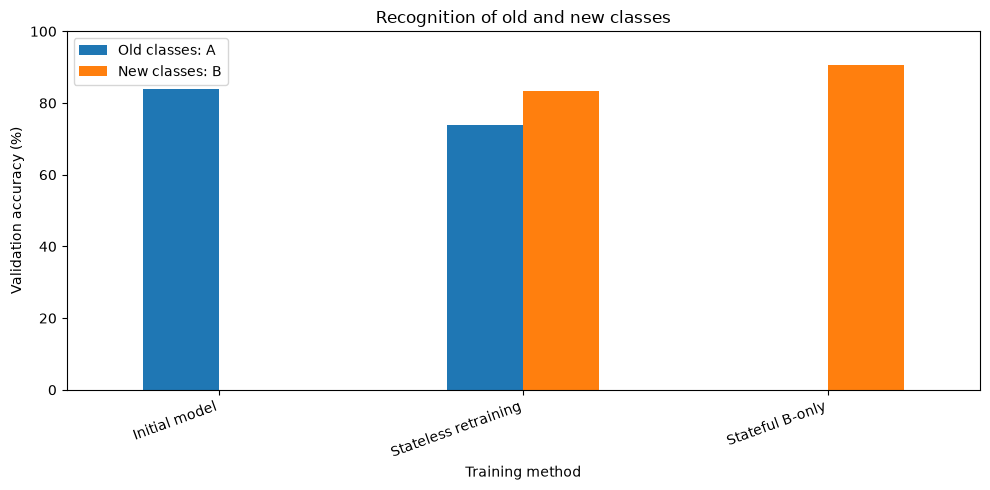

In [22]:
comparison_df.set_index("Model")[
    [
        "A validation accuracy (%)",
        "B validation accuracy (%)"
    ]
].plot.bar(figsize=(10, 5))

plt.title("Recognition of old and new classes")
plt.xlabel("Training method")
plt.ylabel("Validation accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20, ha="right")
plt.legend(["Old classes: A", "New classes: B"])
plt.tight_layout()
plt.show()

**Implementing Evaluation Techniques**

In [17]:
#Collect predictions on the untouched test set
models = {
    "Stateless": stateless_model.cpu(),
    "Stateful": stateful_model.cpu()
}

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)


def collect_predictions(model, loader):
    model.eval()

    predictions = []
    true_labels = []

    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images)

            predictions.extend(outputs.argmax(dim=1).numpy())
            true_labels.extend(labels.numpy())

    return np.array(predictions), np.array(true_labels)


stateless_predictions, y_test = collect_predictions(
    models["Stateless"], test_loader
)

stateful_predictions, stateful_labels = collect_predictions(
    models["Stateful"], test_loader
)

assert np.array_equal(y_test, stateful_labels)

print("Test images:", len(y_test))

Test images: 10000


**Simulate an A/B test**

In [18]:
rng = np.random.default_rng(42)

group_a_indices = []
group_b_indices = []

for class_id in range(10):
    indices = np.flatnonzero(y_test == class_id)
    rng.shuffle(indices)

    midpoint = len(indices) // 2

    group_a_indices.extend(indices[:midpoint])
    group_b_indices.extend(indices[midpoint:])

group_a_indices = np.array(group_a_indices)
group_b_indices = np.array(group_b_indices)

print("Group A requests:", len(group_a_indices))
print("Group B requests:", len(group_b_indices))

Group A requests: 5000
Group B requests: 5000


In [19]:
#Compute accuracy and macro F1 without needing another library
def calculate_metrics(labels, predictions):
    accuracy = np.mean(labels == predictions)

    class_f1_scores = []

    for class_id in range(10):
        tp = np.sum(
            (labels == class_id) & (predictions == class_id)
        )
        fp = np.sum(
            (labels != class_id) & (predictions == class_id)
        )
        fn = np.sum(
            (labels == class_id) & (predictions != class_id)
        )

        denominator = 2 * tp + fp + fn

        class_f1_scores.append(
            2 * tp / denominator if denominator else 0.0
        )

    return accuracy, np.mean(class_f1_scores)


ab_results = {}

for group, model_name, indices, predictions in [
    ("A", "Stateless", group_a_indices, stateless_predictions),
    ("B", "Stateful", group_b_indices, stateful_predictions)
]:
    acc, macro_f1 = calculate_metrics(
        y_test[indices],
        predictions[indices]
    )

    ab_results[group] = (acc, macro_f1)

    print(
        f"Group {group} — {model_name}: "
        f"Accuracy = {acc:.2%}, Macro F1 = {macro_f1:.4f}"
    )

difference = ab_results["A"][0] - ab_results["B"][0]

print(
    f"\nAccuracy difference (A minus B): "
    f"{difference * 100:+.2f} percentage points"
)

Group A — Stateless: Accuracy = 76.78%, Macro F1 = 0.7631
Group B — Stateful: Accuracy = 45.44%, Macro F1 = 0.3067

Accuracy difference (A minus B): +31.34 percentage points


The A/B technic identify which model achieved higher test accuracy and macro F1, and report the differences. The groups were balanced across classes, which improves comparability.

Based on the result, the stateless model correctly classified about 76.78% out of every 100 images, compared with only 45.44% out of 100 for the stateful model. Its accuracy was 31.34 percentage points higher.
The higher macro F1 shows that the stateless model achieved a better balance of precision and recall across the ten classes than the stateful model 

**Bandit Algorithm for Model Selection**
Note that bandit updates its estimates using only the selected model’s feedback. It does not update model weights.

In [20]:
epsilon = 0.10
rng = np.random.default_rng(123)

model_names = ["Stateless", "Stateful"]

# Row 0 contains stateless predictions; row 1 contains stateful predictions
prediction_table = np.vstack([
    stateless_predictions,
    stateful_predictions
])

selection_counts = np.zeros(2, dtype=int)
estimated_rewards = np.zeros(2, dtype=float)

# Treat each test image as one request, in random order
request_order = rng.permutation(len(y_test))

rewards = []
selected_arms = []
estimate_history = []

for step, image_index in enumerate(request_order):
    # Try each model once before applying epsilon-greedy
    if step < 2:
        arm = step

    elif rng.random() < epsilon:
        arm = int(rng.integers(2))

    else:
        # Break ties randomly
        best_arms = np.flatnonzero(
            estimated_rewards == estimated_rewards.max()
        )
        arm = int(rng.choice(best_arms))

    prediction = prediction_table[arm, image_index]

    # Simulated feedback: reveal the true label after prediction
    reward = int(prediction == y_test[image_index])

    selection_counts[arm] += 1

    # Update only the selected model's estimate
    estimated_rewards[arm] += (
        reward - estimated_rewards[arm]
    ) / selection_counts[arm]

    rewards.append(reward)
    selected_arms.append(arm)
    estimate_history.append(estimated_rewards.copy())

rewards = np.array(rewards)
selected_arms = np.array(selected_arms)
estimate_history = np.array(estimate_history)

print(f"Bandit overall accuracy: {rewards.mean():.2%}")

for arm, name in enumerate(model_names):
    print(
        f"{name}: "
        f"selected {selection_counts[arm]} times "
        f"({selection_counts[arm] / len(rewards):.2%}), "
        f"observed accuracy = {estimated_rewards[arm]:.2%}"
    )

Bandit overall accuracy: 76.10%
Stateless: selected 9518 times (95.18%), observed accuracy = 77.53%
Stateful: selected 482 times (4.82%), observed accuracy = 47.93%


The bandit tecchnic achieved 76.10% overall accuracy. That is the model correctly classified about 76.10% out of every 100 requests.
The stateless model received most requests because its estimated accuracy was higher. 